# Libraries

In [1]:
from Lib.MultiLayerNet import *

# Tunning Parameters

In [24]:
steps=20000
lr=1e-3
N = 500

# Functions

In [25]:
def f(x):
    y=np.sin(x)
    return y 

# Generate data

In [26]:
# get the analytical solution over the full domain
x = 2 * np.pi * lhs(1, N) # Latin Hypercube sampling for collocation points 
y = f(x)
print(x.shape, y.shape)


(500, 1) (500, 1)


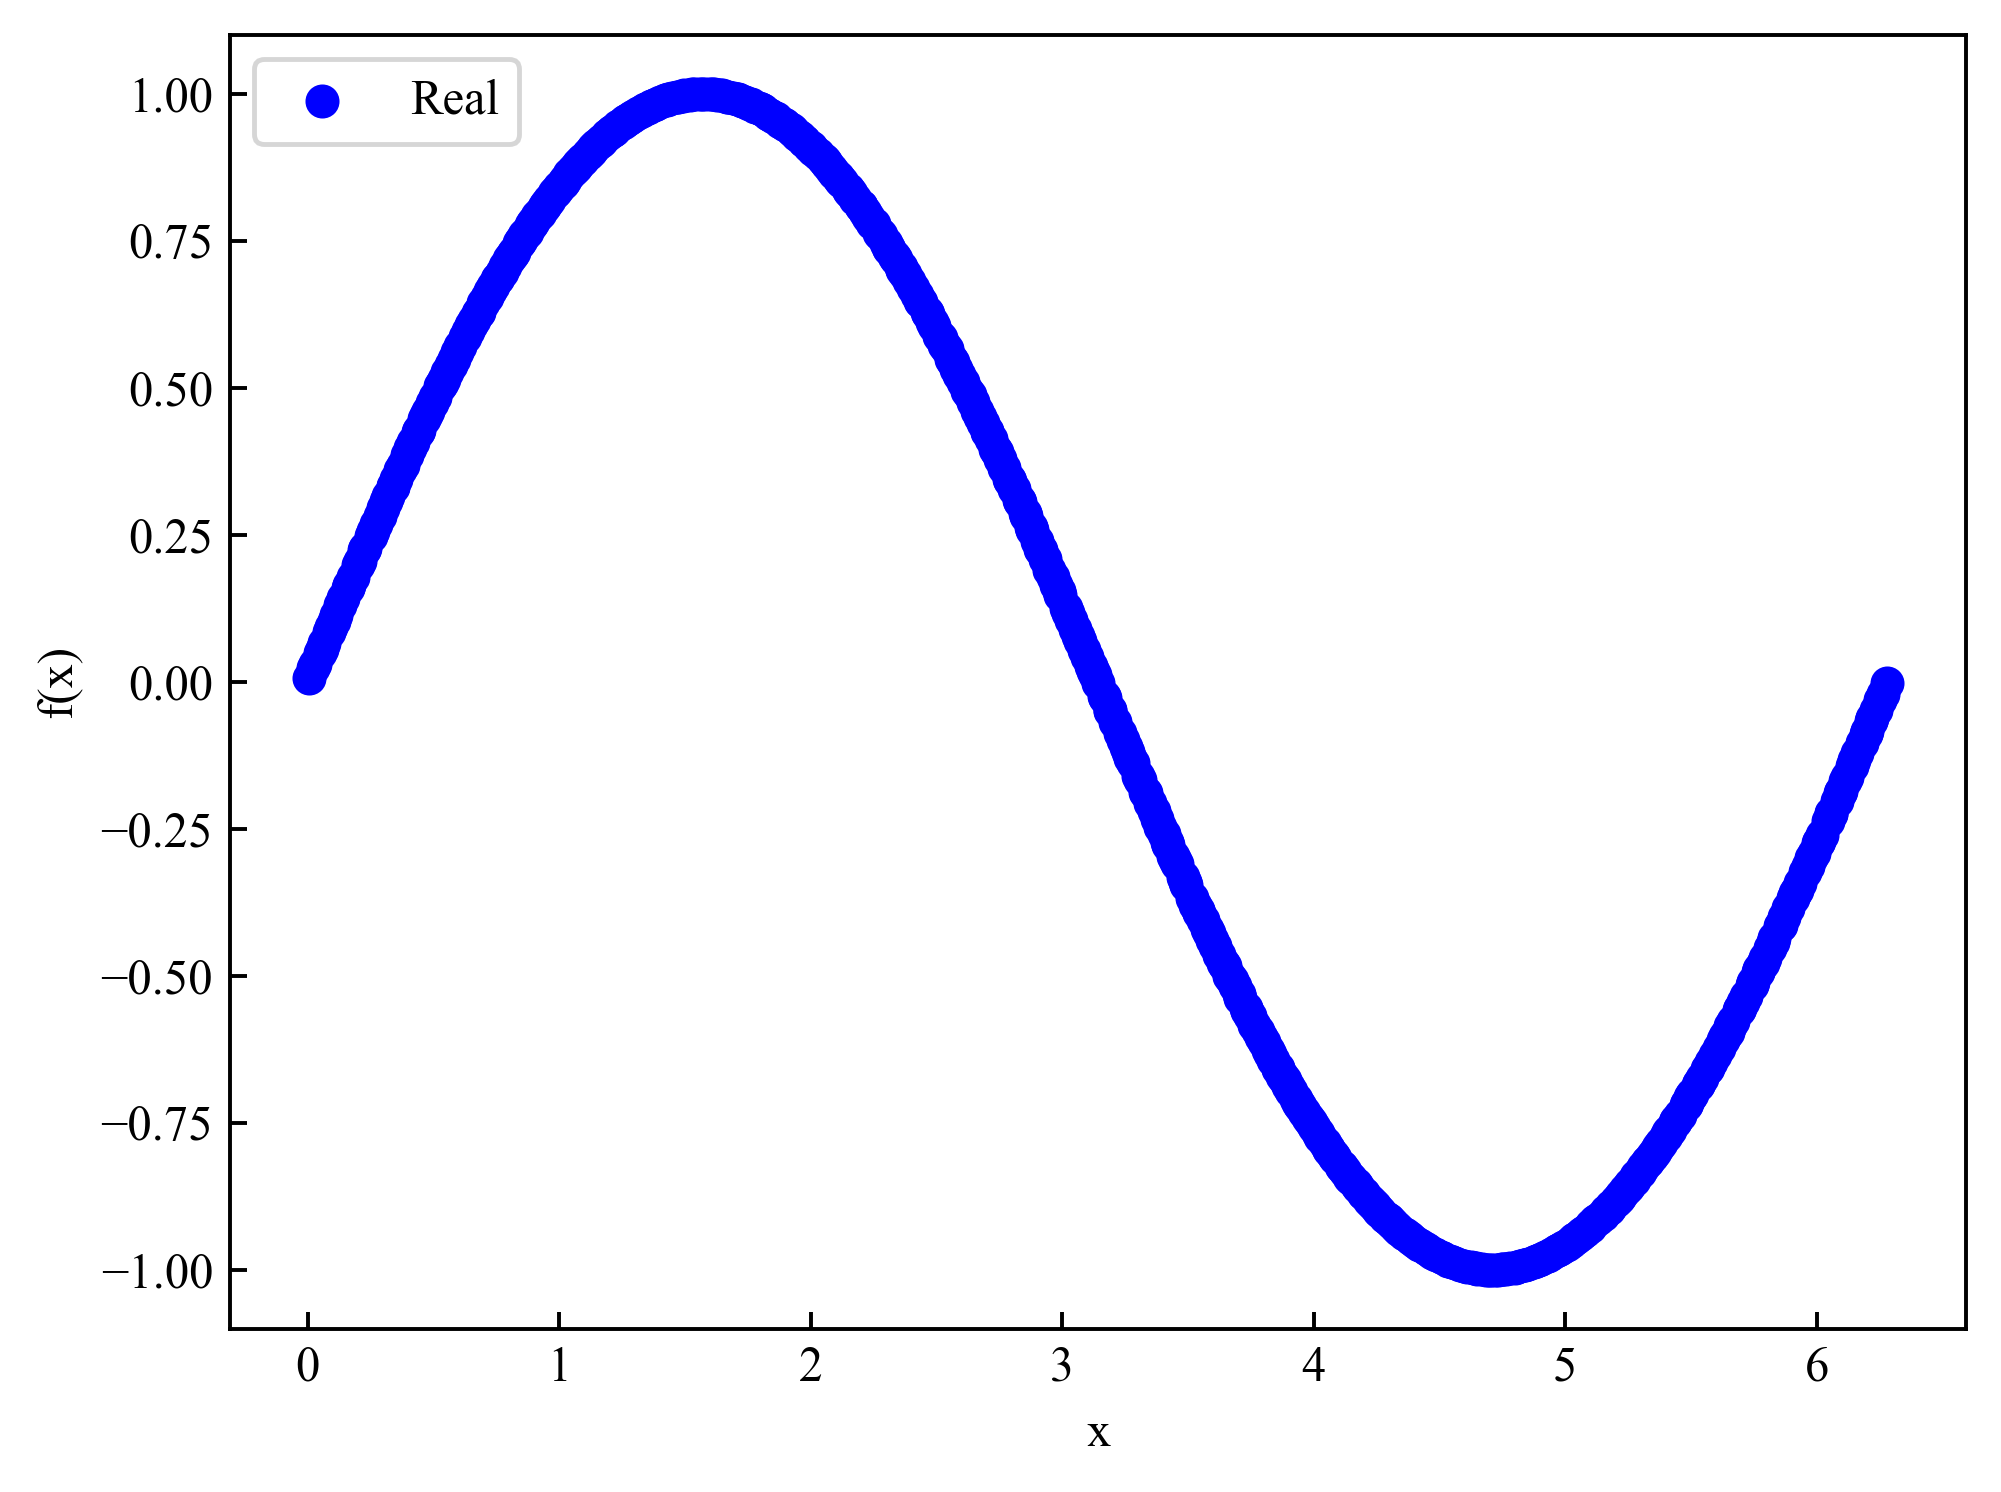

In [27]:
fig, ax1 = plt.subplots()
ax1.scatter(x,y,color='blue',label='Real')
ax1.set_xlabel('x',color='black')
ax1.set_ylabel('f(x)',color='black')
ax1.tick_params(axis='y', color='black')
ax1.legend(loc = 'upper left')

In [28]:
x_train = torch.from_numpy(x)
y_train = torch.from_numpy(y)

# Train Neural Network

In [29]:
x_train=x_train.float().to(dev)
y_train=y_train.float().to(dev)

# Set Neural Network
layers = [1,30,30,30,1]
model = MultiLayerNet(layers, init=True)
model.to(dev)
optimizer = torch.optim.Adam(model.parameters(),lr=lr,amsgrad=False)

Constructor: Init Network!


In [30]:
start_time = time.time()
it_time = time.time()
for i in range(steps):
    optimizer.zero_grad()
    yh = model(x_train)
    loss = torch.mean(torch.square(yh-y_train)) # use mean squared error 
    loss.backward()
    optimizer.step()
    if i%(steps/10)==0:
      print('Iter: %d  Loss: %.5e  Time: %.3e'
                    % (i, loss.item(), time.time() - it_time))
      torch.save(model.state_dict(), './output/Case1/model.pt')
      it_time = time.time()

Iter: 0  Loss: 4.72052e-01  Time: 1.999e-03
Iter: 2000  Loss: 1.34632e-05  Time: 1.042e+00
Iter: 4000  Loss: 2.02092e-06  Time: 1.097e+00
Iter: 6000  Loss: 1.86512e-06  Time: 1.155e+00
Iter: 8000  Loss: 6.75551e-06  Time: 1.104e+00
Iter: 10000  Loss: 2.46471e-07  Time: 1.077e+00
Iter: 12000  Loss: 1.83751e-07  Time: 1.164e+00
Iter: 14000  Loss: 1.10392e-07  Time: 1.190e+00
Iter: 16000  Loss: 4.37376e-06  Time: 1.100e+00
Iter: 18000  Loss: 1.78103e-07  Time: 1.117e+00


In [31]:
x_test = torch.linspace(0,2*np.pi,N).view(-1,1)
y_pred = model(x_test)

x_test = x_test.detach().cpu().numpy()
y_pred = y_pred.detach().cpu().numpy()

y_real = f(x_test)

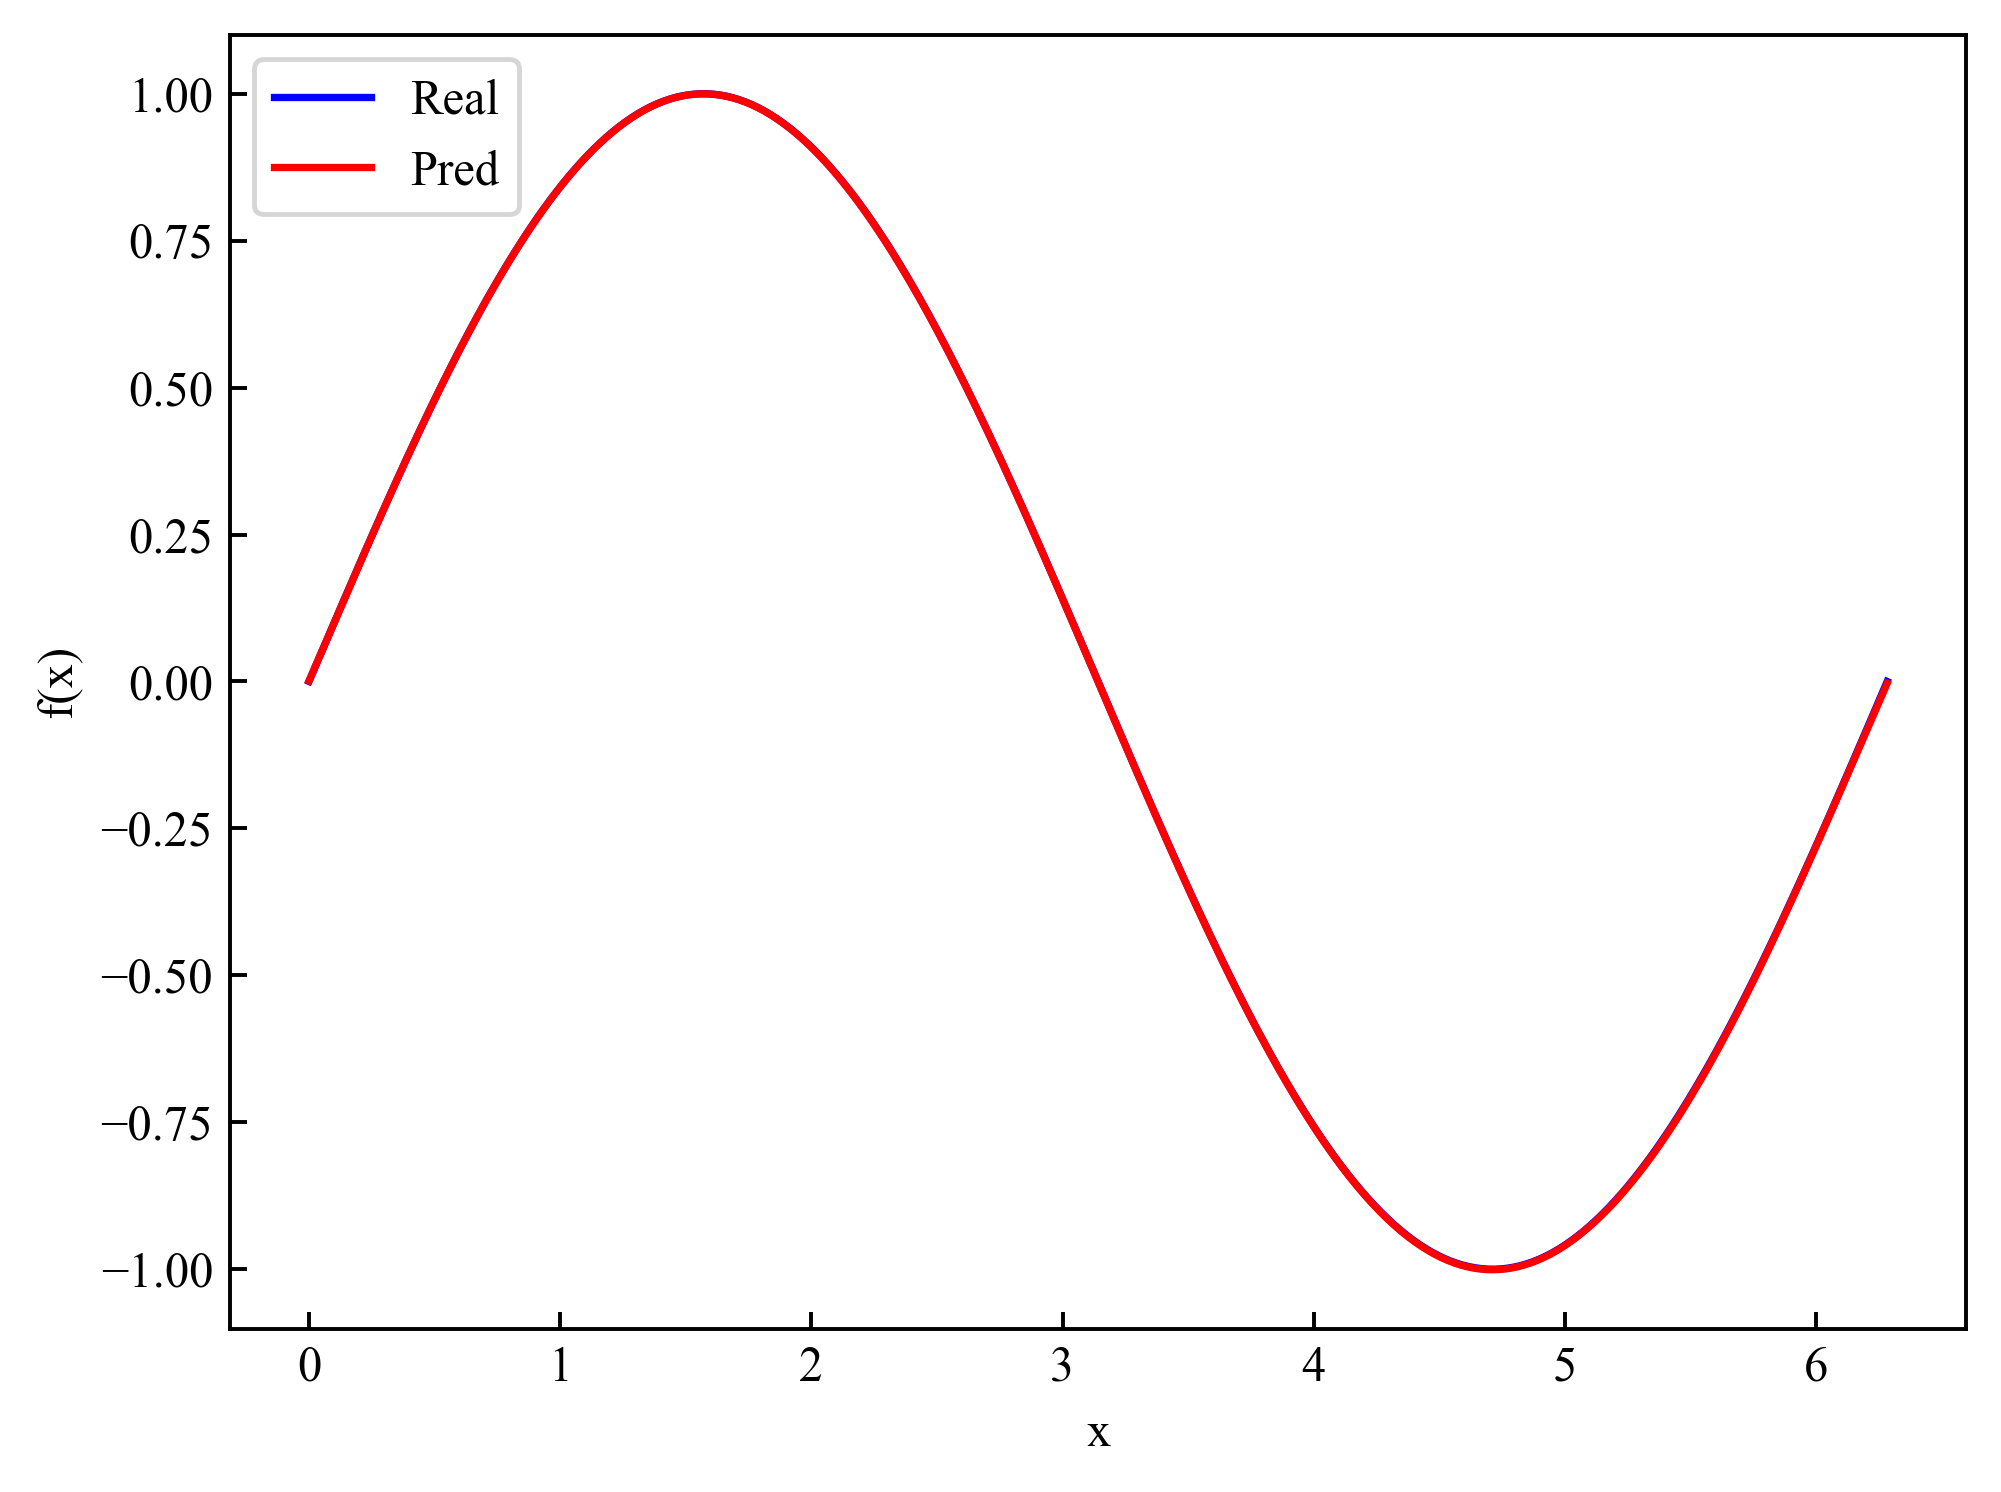

In [32]:
fig, ax1 = plt.subplots()
ax1.plot(x_test,y_real,color='blue',label='Real')
ax1.plot(x_test,y_pred,':',color='red',label='Pred')
ax1.set_xlabel('x',color='black')
ax1.set_ylabel('f(x)',color='black')
ax1.tick_params(axis='y', color='black')
ax1.legend(loc = 'upper left')

In [33]:
print('MSE:', np.mean(np.square(y_real-y_pred)))

MSE: 7.49793e-07
